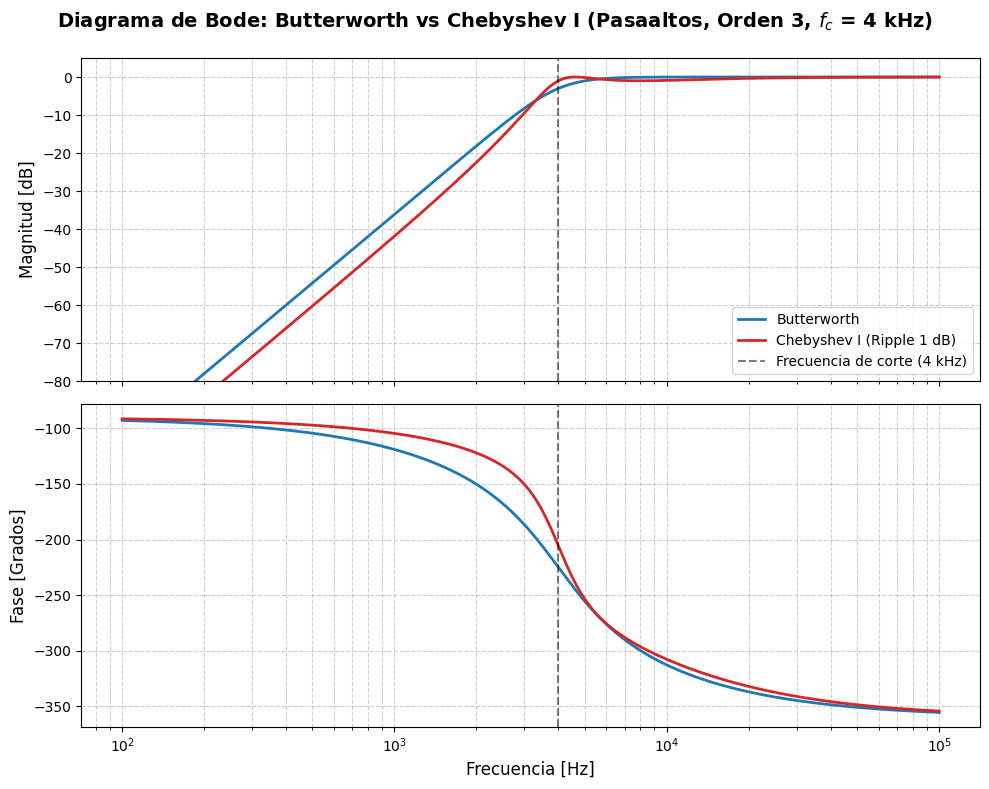

In [ ]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt

# Parámetros del Pasaaltos: Orden 3, Frecuencia de corte 4 kHz
N = 3
fc = 4000  # Hz
wc = 2 * np.pi * fc
Ap = 1     # Rizado de 1 dB

# Funciones de transferencia ('ba') para Pasaaltos
b_butt, a_butt = sig.butter(N, wc, btype='highpass', analog=True, output='ba')
b_cheb, a_cheb = sig.cheby1(N, Ap, wc, btype='highpass', analog=True, output='ba')

# Sistemas LTI
sys_butt = sig.lti(b_butt, a_butt)
sys_cheb = sig.lti(b_cheb, a_cheb)

# Vector de frecuencias (de 100 Hz a 100 kHz)
w_sweep = np.logspace(np.log10(2*np.pi*100), np.log10(2*np.pi*100000), 1000)

# Calcular Bode
w_b, mag_b, phase_b = sig.bode(sys_butt, w_sweep)
w_c, mag_c, phase_c = sig.bode(sys_cheb, w_sweep)

# Frecuencia en Hz
f_hz = w_b / (2 * np.pi)

# Configuración del gráfico
fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
fig.suptitle('Diagrama de Bode: Butterworth vs Chebyshev I (Pasaaltos, Orden 3, $f_c$ = 4 kHz)', fontsize=14, fontweight='bold')

# --- Gráfico de Magnitud ---
ax_mag.semilogx(f_hz, mag_b, label='Butterworth', color='#1f77b4', linewidth=2)
ax_mag.semilogx(f_hz, mag_c, label='Chebyshev I (Ripple 1 dB)', color='#d62728', linewidth=2)
ax_mag.axvline(fc, color='black', linestyle='--', alpha=0.5, label='Frecuencia de corte (4 kHz)')
ax_mag.set_ylabel('Magnitud [dB]', fontsize=12)
ax_mag.set_ylim(-80, 5)
ax_mag.grid(True, which="both", ls="--", alpha=0.6)
ax_mag.legend(loc='lower right')

# --- Gráfico de Fase ---
ax_phase.semilogx(f_hz, phase_b, color='#1f77b4', linewidth=2)
ax_phase.semilogx(f_hz, phase_c, color='#d62728', linewidth=2)
ax_phase.axvline(fc, color='black', linestyle='--', alpha=0.5)
ax_phase.set_xlabel('Frecuencia [Hz]', fontsize=12)
ax_phase.set_ylabel('Fase [Grados]', fontsize=12)
ax_phase.grid(True, which="both", ls="--", alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.92)

# Guardar imagen
plt.savefig('bode_teorico_hp_comparacion.png', dpi=300)
plt.show()